## 1) Environment, Secrets and GPU Check

# Task 2B — QLoRA Fine-Tuning: Qwen2.5-1.5B-Instruct General-Practice Symptom-Intake Agent

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Nipuna-Tennakoon/CDAZZDEV-MLE-Nipuna-Tennakoon/blob/main/task2_genai/notebooks/02_finetuning.ipynb)

Fine-tunes **Qwen/Qwen2.5-1.5B-Instruct** with **QLoRA (4-bit NF4)** on the dataset built in
`01_data_generation.ipynb`, on a **Google Colab free T4 GPU**. Every metric is tracked in
**Weights & Biases**.

| Step | What happens |
|---|---|
| 1 | Environment, secrets, GPU check |
| 2 | Hyperparameters — each one justified |
| 3 | Weights & Biases run + dataset artifact (lineage) |
| 4 | Data loading, chat-template tokenisation, loss masking |
| 5 | 4-bit NF4 base model + LoRA adapters (PEFT) |
| 6 | Training with per-epoch train / validation loss |
| 7 | Save adapter → `merge_and_unload()` → merged fp16 model |
| 8 | Smoke test + push merged model to Hugging Face Hub |
| 9 | OOM / debugging log |

> Runtime: **Runtime → Change runtime type → T4 GPU**. Add `HF_TOKEN`, `HF_REPO_ID`,
> `WANDB_API_KEY` (and optionally `WANDB_PROJECT`, `WANDB_ENTITY`) to **Colab Secrets**.

In [ ]:
import sys, os, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
GITHUB_REPO_URL = "https://github.com/Nipuna-Tennakoon/CDAZZDEV-MLE-Nipuna-Tennakoon.git"

if IN_COLAB:
    repo_dir = Path("/content/CDAZZDEV-MLE-Nipuna-Tennakoon")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", GITHUB_REPO_URL, str(repo_dir)], check=True)
    else:
        # Re-running in the same session: pick up any data / code pushed since the first clone.
        subprocess.run(["git", "-C", str(repo_dir), "pull", "--ff-only"], check=True)
    os.chdir(repo_dir / "task2_genai" / "notebooks")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-U",
         "transformers>=4.56", "peft>=0.13", "bitsandbytes>=0.45", "accelerate>=1.0",
         "datasets>=3.0", "wandb>=0.18", "huggingface_hub>=0.25", "python-dotenv"],
        check=True,
    )
    # If Colab reports already-imported transformers, use Runtime -> Restart session once, then re-run.

In [2]:
import gc
import json
import math
import random
import time
from dataclasses import asdict, dataclass, field
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import wandb
from datasets import Dataset
from dotenv import load_dotenv
from peft import LoraConfig, PeftModel, TaskType, get_peft_model, prepare_model_for_kbit_training
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
    Trainer,
    TrainerCallback,
    TrainingArguments,
    set_seed,
)


def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    raise FileNotFoundError("Could not locate repo root (pyproject.toml)")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
TASK_DIR = REPO_ROOT / "task2_genai"
DATA_DIR = TASK_DIR / "data"
MODELS_DIR = TASK_DIR / "models"
REPORTS_DIR = TASK_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

load_dotenv(REPO_ROOT / ".env")


def get_secret(name: str, default: str | None = None) -> str | None:
    """Colab Secrets first, then environment / .env. Nothing is hard-coded (assessment rule 2.3)."""
    if IN_COLAB:
        try:
            from google.colab import userdata
            value = userdata.get(name)
            if value:
                return value
        except Exception:
            pass
    return os.getenv(name) or default


HF_TOKEN = get_secret("HF_TOKEN")
HF_REPO_ID = get_secret("HF_REPO_ID")
WANDB_API_KEY = get_secret("WANDB_API_KEY")
WANDB_PROJECT = get_secret("WANDB_PROJECT", "cdazzdev-task2-gp-intake")
WANDB_ENTITY = get_secret("WANDB_ENTITY")

assert torch.cuda.is_available(), "QLoRA needs a CUDA GPU — switch the Colab runtime to T4 GPU"
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3
BF16_OK = torch.cuda.is_bf16_supported()
print(f"GPU: {GPU_NAME}  ({GPU_MEM_GB:.1f} GB)  bf16 supported: {BF16_OK}")
print(f"torch {torch.__version__}")

GPU: Tesla T4  (14.6 GB)  bf16 supported: True
torch 2.11.0+cu130


## 2) Hyperparameters — Every Choice Justified

| Parameter | Value | Why |
|---|---|---|
| Base model | `Qwen/Qwen2.5-1.5B-Instruct` | Fits a free T4 comfortably in 4-bit (~1.2 GB weights), ships a proper chat template, and is a **different family** from the Llama / GPT-OSS teachers (teacher ≠ student). Instruct-tuned, so fine-tuning only has to teach the *intake behaviour*, not chat formatting. |
| Quantisation | 4-bit **NF4**, double quant | NF4 is information-theoretically optimal for normally-distributed weights (QLoRA paper). Double quantisation also quantises the scale constants → saves ~0.4 bit/param. |
| Compute dtype | `float16` (bf16 if supported) | The T4 (Turing) has no bf16 support, so fp16 is the fastest safe choice there. The code switches to bf16 automatically on Ampere+ GPUs (more stable range). |
| LoRA rank `r` | **16** | The task is behaviour/style adaptation on ~240 short dialogues, not new knowledge. r = 8 under-fits 7 projection types; r = 64 adds parameters the small dataset cannot support and raises over-fitting risk. 16 gives ~18.5 M trainable params (~1.2 % of the model). |
| LoRA alpha | **32** (= 2·r) | Effective scale `alpha / r = 2`, the common default. Tying alpha to r keeps the update magnitude stable if r is tuned later, so the learning rate does not need re-tuning. |
| LoRA dropout | **0.05** | Light regularisation: the dataset is small, so some dropout helps against memorisation, but with only ~45 optimiser steps a larger value such as 0.1 mainly slows learning. |
| Target modules | `q,k,v,o,gate,up,down_proj` | QLoRA paper: adapting **all linear layers** is needed to match full fine-tuning quality; attention-only LoRA under-performs. |
| Learning rate | **2e-4** | Standard QLoRA value for small models. LoRA adapters start at zero (B = 0) and need a ~10× higher LR than full fine-tuning (typically ~1e-5). |
| LR scheduler | **cosine**, warmup **5 %** of steps | Warmup avoids large early updates while Adam statistics settle; cosine decay lets the last epoch refine instead of oscillating — gives the smooth, decreasing validation curve the task requires. |
| Epochs | **3** (+ early stopping, patience 1) | 240 examples × 3 = 720 example passes. More epochs on a small synthetic set raise the risk of memorisation (val loss turning up). Early stopping + `load_best_model_at_end` protect against that. |
| Per-device batch | **4** | Fits a 15 GB T4 at 512 tokens with gradient checkpointing, with headroom. |
| Gradient accumulation | **4** | Effective batch **16** → smoother gradients than 4, and ~15 optimiser steps per epoch, enough for warmup + cosine to be meaningful. |
| Max sequence length | **512** | Dialogues have ≤ 4 exchanges; the length analysis in section 4 shows p99 is well under 512, so **0 % truncation** while avoiding padding waste. Asserted in code. |
| Optimiser | `paged_adamw_8bit` | Paged optimiser states move to CPU on memory spikes (QLoRA paper) → prevents OOM on the T4; 8-bit states cut optimiser memory ~4×. |
| Weight decay | **0.0** | Adapter params are few and already regularised by dropout + low rank; decay mostly slows learning on such short schedules. |
| Max grad norm | **0.3** | QLoRA paper value; clipping keeps fp16 training stable. |
| Gradient checkpointing | on | Trades ~20 % extra compute for a large cut in activation memory — the main OOM lever on a T4. |
| Loss masking | assistant target only | Prompt tokens get label `-100`, so the model learns to **produce the intake reply**, not to imitate patient text or the system prompt. |
| Seed | 42 | Reproducibility of data order, LoRA init and dropout. |

In [3]:
@dataclass
class Config:
    # model
    base_model: str = "Qwen/Qwen2.5-1.5B-Instruct"
    max_seq_length: int = 512
    # quantisation
    load_in_4bit: bool = True
    bnb_4bit_quant_type: str = "nf4"
    bnb_4bit_use_double_quant: bool = True
    # LoRA
    lora_r: int = 16
    lora_alpha: int = 32
    lora_dropout: float = 0.05
    lora_target_modules: list[str] = field(default_factory=lambda: [
        "q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    # optimisation
    learning_rate: float = 2e-4
    lr_scheduler_type: str = "cosine"
    warmup_ratio: float = 0.05
    num_train_epochs: int = 3
    per_device_train_batch_size: int = 4
    per_device_eval_batch_size: int = 4
    gradient_accumulation_steps: int = 4
    optim: str = "paged_adamw_8bit"
    weight_decay: float = 0.0
    max_grad_norm: float = 0.3
    early_stopping_patience: int = 1
    logging_steps: int = 5
    seed: int = 42


CFG = Config()
COMPUTE_DTYPE = torch.bfloat16 if BF16_OK else torch.float16

MODEL_SHORT = CFG.base_model.split("/")[-1]
RUN_NAME = f"{MODEL_SHORT}-qlora-r{CFG.lora_r}-{time.strftime('%Y%m%d-%H%M%S')}"
RUN_DIR = MODELS_DIR / RUN_NAME
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
ADAPTER_DIR = RUN_DIR / "adapter"
MERGED_DIR = RUN_DIR / "merged"

set_seed(CFG.seed)
random.seed(CFG.seed)
np.random.seed(CFG.seed)

print(f"Run: {RUN_NAME}")
print(json.dumps(asdict(CFG), indent=2))

Run: Qwen2.5-1.5B-Instruct-qlora-r16-20261011-102319
{
  "base_model": "Qwen/Qwen2.5-1.5B-Instruct",
  "max_seq_length": 512,
  "load_in_4bit": true,
  "bnb_4bit_quant_type": "nf4",
  "bnb_4bit_use_double_quant": true,
  "lora_r": 16,
  "lora_alpha": 32,
  "lora_dropout": 0.05,
  "lora_target_modules": [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj"
  ],
  "learning_rate": 0.0002,
  "lr_scheduler_type": "cosine",
  "warmup_ratio": 0.05,
  "num_train_epochs": 3,
  "per_device_train_batch_size": 4,
  "per_device_eval_batch_size": 4,
  "gradient_accumulation_steps": 4,
  "optim": "paged_adamw_8bit",
  "weight_decay": 0.0,
  "max_grad_norm": 0.3,
  "early_stopping_patience": 1,
  "logging_steps": 5,
  "seed": 42
}


## 3) Weights & Biases — Run Setup and Dataset Lineage



In [4]:
SPLIT_PATHS = {s: DATA_DIR / f"{s}.jsonl" for s in ("train", "val", "test")}
for s, p in SPLIT_PATHS.items():
    if not p.exists():
        raise FileNotFoundError(f"Missing {p} — run 01_data_generation.ipynb first")

os.environ["WANDB_PROJECT"] = WANDB_PROJECT
os.environ["WANDB_LOG_MODEL"] = "false"   # weights go to the HF Hub, not W&B storage

if WANDB_API_KEY:
    wandb.login(key=WANDB_API_KEY, relogin=True)
else:
    print("WANDB_API_KEY not set — falling back to offline mode (sync later with `wandb sync`).")
    os.environ["WANDB_MODE"] = "offline"

run = wandb.init(
    project=WANDB_PROJECT,
    entity=WANDB_ENTITY,
    name=RUN_NAME,
    job_type="finetune",
    tags=["qlora", "nf4", MODEL_SHORT, "gp-intake", "task2"],
    config={**asdict(CFG), "compute_dtype": str(COMPUTE_DTYPE), "gpu": GPU_NAME},
)

data_artifact = wandb.Artifact("gp-intake-dataset", type="dataset",
                               description="Synthetic general-practice symptom-intake chat data (80/10/10)")
for p in SPLIT_PATHS.values():
    data_artifact.add_file(str(p))
stats_path = REPORTS_DIR / "dataset_stats.json"
if stats_path.exists():
    data_artifact.add_file(str(stats_path))
run.use_artifact(data_artifact)
print(f"W&B run: {run.url}")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: tennakoon1997 (tennakoon1997-nipunadev) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B run: https://wandb.ai/tennakoon1997-nipunadev/cdazzdev-task2-skin-intake/runs/qvftf3ih


## 4) Load Data, Apply Chat Template, Mask the Prompt



In [5]:
def load_jsonl(path: Path) -> list[dict[str, Any]]:
    return [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]


raw = {s: load_jsonl(p) for s, p in SPLIT_PATHS.items()}
for s, recs in raw.items():
    print(f"{s:<5} {len(recs):>4} records")

tokenizer = AutoTokenizer.from_pretrained(CFG.base_model)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"   # right padding for training (causal LM labels stay aligned)


def split_prompt_target(messages: list[dict[str, str]]) -> tuple[str, str]:
    """Return (prompt_text, target_text) using the model's chat template.
    target_text = the final assistant reply + its end-of-turn token."""
    assert messages[-1]["role"] == "assistant"
    prompt_text = tokenizer.apply_chat_template(messages[:-1], tokenize=False, add_generation_prompt=True)
    full_text = tokenizer.apply_chat_template(messages, tokenize=False)
    assert full_text.startswith(prompt_text), "chat template prefix mismatch"
    return prompt_text, full_text[len(prompt_text):]


def encode(record: dict[str, Any]) -> dict[str, list[int]]:
    prompt_text, target_text = split_prompt_target(record["messages"])
    prompt_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
    target_ids = tokenizer(target_text, add_special_tokens=False)["input_ids"]
    input_ids = (prompt_ids + target_ids)[: CFG.max_seq_length]
    labels = ([-100] * len(prompt_ids) + target_ids)[: CFG.max_seq_length]
    return {"input_ids": input_ids, "attention_mask": [1] * len(input_ids), "labels": labels}


# Justify max_seq_length with data, and fail loudly if anything would be truncated.
lengths = [len(tokenizer(tokenizer.apply_chat_template(r["messages"], tokenize=False),
                         add_special_tokens=False)["input_ids"]) for s in raw for r in raw[s]]
p50, p95, p99 = np.percentile(lengths, [50, 95, 99])
n_trunc = sum(l > CFG.max_seq_length for l in lengths)
print(f"Token lengths — p50={p50:.0f}  p95={p95:.0f}  p99={p99:.0f}  max={max(lengths)}")
print(f"Records longer than max_seq_length={CFG.max_seq_length}: {n_trunc}")
assert n_trunc == 0, "Raise max_seq_length — some targets would be truncated"
wandb.log({"data/token_len_p50": p50, "data/token_len_p95": p95, "data/token_len_max": max(lengths)})

train_ds = Dataset.from_list(raw["train"]).map(encode, remove_columns=list(raw["train"][0].keys()))
val_ds = Dataset.from_list(raw["val"]).map(encode, remove_columns=list(raw["val"][0].keys()))

collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, label_pad_token_id=-100, pad_to_multiple_of=8)

# Sanity check: show exactly which tokens are trained on.
ex = train_ds[0]
print("\n--- PROMPT (masked) ---")
print(tokenizer.decode([t for t, l in zip(ex["input_ids"], ex["labels"]) if l == -100])[-300:])
print("--- TARGET (trained) ---")
print(tokenizer.decode([t for t in ex["labels"] if t != -100]))

train  240 records
val     30 records
test    30 records


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Token lengths — p50=116  p95=250  p99=273  max=293
Records longer than max_seq_length=512: 0


Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]


--- PROMPT (masked) ---
ime, to gather the patient's symptoms about any health concern. Do not diagnose or suggest possible conditions, and do not recommend or prescribe any medication or treatment.<|im_end|>
<|im_start|>user
My knee hurts a little, but I think I just need to exercise more.<|im_end|>
<|im_start|>assistant

--- TARGET (trained) ---
It's good to know you're thinking about staying active. Can you describe when the knee pain started and if it was sudden or gradual?<|im_end|>



## 5) Load the 4-bit NF4 Base Model and Attach LoRA Adapters

In [6]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=CFG.load_in_4bit,
    bnb_4bit_quant_type=CFG.bnb_4bit_quant_type,
    bnb_4bit_use_double_quant=CFG.bnb_4bit_use_double_quant,
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)

model = AutoModelForCausalLM.from_pretrained(
    CFG.base_model,
    quantization_config=bnb_config,
    device_map={"": 0},
    dtype=COMPUTE_DTYPE,
)
model.config.use_cache = False   # KV cache is useless during training and conflicts with checkpointing

# Casts norms to fp32, enables input grads + gradient checkpointing for k-bit training.
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

lora_config = LoraConfig(
    r=CFG.lora_r,
    lora_alpha=CFG.lora_alpha,
    lora_dropout=CFG.lora_dropout,
    target_modules=CFG.lora_target_modules,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
footprint_gb = model.get_memory_footprint() / 1024**3
print(f"Memory footprint: {footprint_gb:.2f} GB")
wandb.run.summary.update({"model/trainable_params": trainable, "model/total_params": total,
                          "model/trainable_pct": 100 * trainable / total, "model/footprint_gb": footprint_gb})

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
Memory footprint: 1.55 GB


## 6) Train — Per-Epoch Train and Validation Loss


In [7]:
class EpochLossCallback(TrainerCallback):
    """Collects mean train loss per epoch and eval loss per epoch."""

    def __init__(self):
        self.train_losses: dict[int, list[float]] = {}
        self.val_loss: dict[int, float] = {}

    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs and "loss" in logs and state.epoch is not None:
            epoch = max(1, math.ceil(state.epoch - 1e-9))
            self.train_losses.setdefault(epoch, []).append(float(logs["loss"]))

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if metrics and "eval_loss" in metrics:
            epoch = int(round(state.epoch or 0))
            self.val_loss[epoch] = float(metrics["eval_loss"])

    def table(self) -> pd.DataFrame:
        epochs = sorted(set(self.train_losses) | set(self.val_loss))
        return pd.DataFrame({
            "epoch": epochs,
            "train_loss": [np.mean(self.train_losses[e]) if e in self.train_losses else np.nan for e in epochs],
            "val_loss": [self.val_loss.get(e, np.nan) for e in epochs],
        })


epoch_cb = EpochLossCallback()

training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    run_name=RUN_NAME,
    report_to=["wandb"],
    num_train_epochs=CFG.num_train_epochs,
    per_device_train_batch_size=CFG.per_device_train_batch_size,
    per_device_eval_batch_size=CFG.per_device_eval_batch_size,
    gradient_accumulation_steps=CFG.gradient_accumulation_steps,
    learning_rate=CFG.learning_rate,
    lr_scheduler_type=CFG.lr_scheduler_type,
    warmup_steps=CFG.warmup_ratio,   # transformers 5: a float in [0, 1) is a ratio of total steps
    optim=CFG.optim,
    weight_decay=CFG.weight_decay,
    max_grad_norm=CFG.max_grad_norm,
    fp16=COMPUTE_DTYPE == torch.float16,
    bf16=COMPUTE_DTYPE == torch.bfloat16,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_strategy="steps",
    logging_steps=CFG.logging_steps,
    logging_first_step=True,
    remove_unused_columns=False,
    seed=CFG.seed,
    data_seed=CFG.seed,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    processing_class=tokenizer,
    callbacks=[epoch_cb, EarlyStoppingCallback(early_stopping_patience=CFG.early_stopping_patience)],
)

steps_per_epoch = math.ceil(len(train_ds) / (CFG.per_device_train_batch_size * CFG.gradient_accumulation_steps))
print(f"Optimizer steps per epoch: {steps_per_epoch}  |  total: {steps_per_epoch * CFG.num_train_epochs}")

Optimizer steps per epoch: 15  |  total: 45


In [8]:
# Baseline validation loss BEFORE any training (epoch 0) — the reference point for improvement.
baseline = trainer.evaluate()
print(f"Epoch 0 (no fine-tuning) val loss: {baseline['eval_loss']:.4f}")

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
try:
    train_result = trainer.train()
except torch.cuda.OutOfMemoryError:
    # Documented recovery path (see section 9): halve the batch, double accumulation so the
    # effective batch size (and therefore the LR schedule) stays the same.
    print("CUDA OOM — retry with per_device_train_batch_size halved and accumulation doubled.")
    raise

train_minutes = (time.time() - t0) / 60
peak_mem_gb = torch.cuda.max_memory_allocated() / 1024**3
print(f"Training time: {train_minutes:.1f} min  |  peak GPU memory: {peak_mem_gb:.2f} GB")
print(train_result.metrics)

Training Loss,Validation Loss,Epoch
No log,2.070358,0


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 151643}.


Epoch 0 (no fine-tuning) val loss: 2.0704


Epoch,Training Loss,Validation Loss
1,1.117277,1.043348
2,0.872898,0.978563
3,0.684643,0.964720


Training time: 14.4 min  |  peak GPU memory: 4.26 GB
{'train_runtime': 862.5461, 'train_samples_per_second': 0.835, 'train_steps_per_second': 0.052, 'total_flos': 1294277697110016.0, 'train_loss': 0.9891781012217203, 'epoch': 3.0}


,epoch,train_loss,val_loss
0,0,NaN,2.0704
1,1,1.5850,1.0433
2,2,0.8529,0.9786
3,3,0.6913,0.9647


Validation loss strictly decreasing across epochs: True


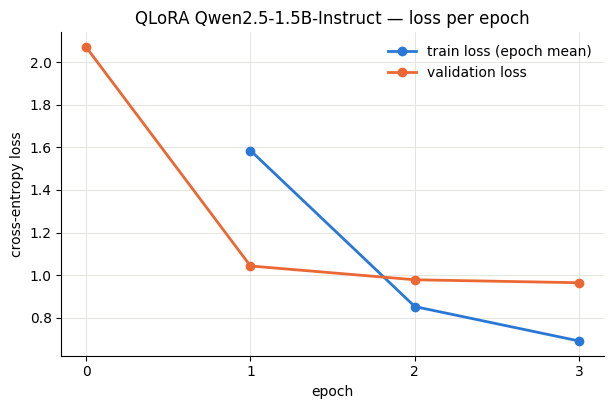

1552

In [9]:
loss_df = epoch_cb.table()
display(loss_df.round(4))

val = loss_df.dropna(subset=["val_loss"])["val_loss"].tolist()
val_decreasing = all(b < a for a, b in zip(val, val[1:]))
print(f"Validation loss strictly decreasing across epochs: {val_decreasing}")
if not val_decreasing:
    print("⚠ Val loss went up at some epoch — the best checkpoint was restored (load_best_model_at_end).")

# Chart: per-epoch train vs validation loss
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(loss_df.epoch, loss_df.train_loss, marker="o", color="#2a78d6", lw=2, label="train loss (epoch mean)")
ax.plot(loss_df.epoch, loss_df.val_loss, marker="o", color="#eb6834", lw=2, label="validation loss")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss")
ax.set_title(f"QLoRA {MODEL_SHORT} — loss per epoch")
ax.set_xticks(loss_df.epoch)
ax.grid(True, color="#e1e0d9", lw=0.6); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False)
loss_png = REPORTS_DIR / "loss_per_epoch.png"
fig.savefig(loss_png, dpi=150, bbox_inches="tight")
plt.show()

# Log per-epoch table + chart to W&B, and persist locally for the README.
wandb.log({
    "epoch_summary/loss_table": wandb.Table(dataframe=loss_df),
    "epoch_summary/loss_chart": wandb.Image(str(loss_png)),
})
wandb.run.summary.update({
    "baseline_val_loss": baseline["eval_loss"],
    "best_val_loss": float(np.nanmin(loss_df.val_loss)),
    "val_loss_decreasing": val_decreasing,
    "train_minutes": train_minutes,
    "peak_gpu_mem_gb": peak_mem_gb,
})
(REPORTS_DIR / "training_metrics.json").write_text(json.dumps({
    "run_name": RUN_NAME,
    "wandb_url": run.url,
    "config": asdict(CFG),
    "per_epoch": loss_df.to_dict(orient="records"),
    "baseline_val_loss": baseline["eval_loss"],
    "val_loss_decreasing": val_decreasing,
    "train_minutes": round(train_minutes, 2),
    "peak_gpu_mem_gb": round(peak_mem_gb, 2),
    "gpu": GPU_NAME,
}, indent=2, default=float), encoding="utf-8")

In [11]:
!pip uninstall -y torchao
import importlib; importlib.invalidate_caches()

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 7) Save the Adapter,


In [12]:
del base_fp16; gc.collect(); torch.cuda.empty_cache()   # free the copy loaded before the crash

from huggingface_hub import HfApi   # back up the adapter first
HfApi(token=HF_TOKEN).create_repo(HF_REPO_ID, private=False, exist_ok=True)
HfApi(token=HF_TOKEN).upload_folder(folder_path=str(ADAPTER_DIR), repo_id=HF_REPO_ID, path_in_repo="adapter")

base_fp16 = AutoModelForCausalLM.from_pretrained(CFG.base_model, dtype=torch.float16, device_map={"": 0})
merged_model = PeftModel.from_pretrained(base_fp16, str(ADAPTER_DIR)).merge_and_unload()
merged_model.config.use_cache = True
MERGED_DIR.mkdir(parents=True, exist_ok=True)
merged_model.save_pretrained(str(MERGED_DIR))
tokenizer.save_pretrained(str(MERGED_DIR))
print(f"Merged model saved -> {MERGED_DIR}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model saved -> /content/CDAZZDEV-MLE-Nipuna-Tennakoon/task2_genai/models/Qwen2.5-1.5B-Instruct-qlora-r16-20261011-102319/merged


## 8) Smoke Test and Push to Hugging Face Hub

A quick greedy-decoding check on three **test** conversations confirms the merged model
loads and behaves. Full quantitative evaluation (ROUGE-L, BERTScore / LLM-as-judge,
hallucination rate) vs. the base model is done in the evaluation notebook.

In [13]:
@torch.no_grad()
def generate_reply(model, messages: list[dict[str, str]], max_new_tokens: int = 96) -> str:
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


merged_model.eval()
smoke_rows = []
for rec in raw["test"][:3]:
    pred = generate_reply(merged_model, rec["messages"][:-1])
    smoke_rows.append({"stage": rec["stage"], "concern": rec["concern"],
                       "last_patient_turn": rec["messages"][-2]["content"],
                       "reference": rec["messages"][-1]["content"], "fine_tuned": pred})
    print(f"[{rec['stage']} / {rec['concern']}]")
    print(f"  patient   : {rec['messages'][-2]['content']}")
    print(f"  reference : {rec['messages'][-1]['content']}")
    print(f"  fine-tuned: {pred}\n")

wandb.log({"smoke_test/samples": wandb.Table(dataframe=pd.DataFrame(smoke_rows))})

[final / skin_hair_nails]
  patient   : I had a mild fever yesterday.
  reference : Thanks, you've mentioned a painful lump on your neck that appeared three days ago, has grown and become tender, and you had a mild fever yesterday. I’ll pass this information to the doctor for review.
  fine-tuned: To summarize, you have a painful, growing lump on your neck that started three days ago with tenderness; you also had a mild fever yesterday. I’ll pass this information to the doctor for review.

[final / skin_hair_nails]
  patient   : No, I haven’t done anything yet.
  reference : You have an itchy, growing red patch on your scalp with hair loss over two weeks, and haven’t tried any treatments yet. I will pass this information to your doctor for review.
  fine-tuned: Understood. You’ve had an itchy patch on your scalp that has been getting bigger and redder over two weeks, without any previous treatments. I’ll pass this information along to the doctor for review.

[final / eye_ear]
  patient

In [14]:
PUSH_TO_HUB = True
HF_PRIVATE = False   # public repo preferred by the assessment

if PUSH_TO_HUB and HF_TOKEN and HF_REPO_ID:
    from huggingface_hub import HfApi

    merged_model.push_to_hub(HF_REPO_ID, token=HF_TOKEN, private=HF_PRIVATE,
                             commit_message=f"Merged QLoRA model from run {RUN_NAME}")
    tokenizer.push_to_hub(HF_REPO_ID, token=HF_TOKEN)
    HfApi(token=HF_TOKEN).upload_folder(folder_path=str(ADAPTER_DIR), repo_id=HF_REPO_ID,
                                        path_in_repo="adapter", commit_message="LoRA adapter weights")
    hf_url = f"https://huggingface.co/{HF_REPO_ID}"
    wandb.run.summary["hf_model_url"] = hf_url
    print(f"Pushed -> {hf_url}")
else:
    print("Skipping Hub push (set PUSH_TO_HUB, HF_TOKEN and HF_REPO_ID to enable).")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...g5qn363/model.safetensors:   0%|          | 21.6kB / 3.09GB            

Validating                    :           |   0%            

...

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpxjp467_5/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


Pushed -> https://huggingface.co/nipunaCBT/qwen2.5-1.5b-skin-intake-qlora


In [15]:
wandb.finish()

data/token_len_max,▁
data/token_len_p50,▁
data/token_len_p95,▁
eval/loss,█▁▁▁
eval/model_preparation_time,▁▁▁▁
eval/runtime,█▁▂▂
eval/samples_per_second,▁█▇▇
eval/steps_per_second,▁█▇▇
train/epoch,▁▁▂▃▃▃▄▅▆▆▆▇███
train/global_step,▁▁▂▃▃▃▄▅▆▆▆▇█████
+3,...
